In [22]:
!pip install -q ultralytics onnx fastapi uvicorn python-multipart httpx

In [23]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import json
import io
import time
import mimetypes

from PIL import Image
from google.colab import files

from ultralytics import YOLO
from ultralytics.utils import ops

print("All libraries imported successfully!")
print("PyTorch Version:", torch.__version__)
print("Ultralytics Version:", __import__("ultralytics").__version__)
print("GPU Available:", torch.cuda.is_available())

All libraries imported successfully!
PyTorch Version: 2.14.1+cpu
Ultralytics Version: 8.4.211
GPU Available: False


In [24]:
model = YOLO("yolov8n.pt")

device = "cuda" if torch.cuda.is_available() else "cpu"

model.model.to(device)
model.model.eval()

print("YOLOv8 model loaded successfully!")
print("Device:", device)
print("Model: YOLOv8 Nano")
print("Number of classes:", len(model.names))

YOLOv8 model loaded successfully!
Device: cpu
Model: YOLOv8 Nano
Number of classes: 80


In [25]:
def validate_request(filename, content_type, image_bytes):

    if not filename:
        raise ValueError("Filename is missing")

    if not content_type.startswith("image/"):
        raise ValueError("Only image files are allowed")

    if len(image_bytes) == 0:
        raise ValueError("Uploaded file is empty")

    if len(image_bytes) > 10 * 1024 * 1024:
        raise ValueError("Image size must be below 10 MB")

    print("Request validation successful!")

    return True

In [26]:
def decode_image(image_bytes):

    image = Image.open(io.BytesIO(image_bytes))

    image = image.convert("RGB")

    image = np.array(image)

    print("Image decoded successfully!")
    print("Image shape:", image.shape)

    return image

In [27]:
def letterbox(image, new_shape=(640, 640)):

    height, width = image.shape[:2]

    ratio = min(
        new_shape[0] / height,
        new_shape[1] / width
    )

    new_width = int(round(width * ratio))
    new_height = int(round(height * ratio))

    resized = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_LINEAR
    )

    pad_width = new_shape[1] - new_width
    pad_height = new_shape[0] - new_height

    pad_width /= 2
    pad_height /= 2

    left = int(round(pad_width - 0.1))
    right = int(round(pad_width + 0.1))

    top = int(round(pad_height - 0.1))
    bottom = int(round(pad_height + 0.1))

    output = cv2.copyMakeBorder(
        resized,
        top,
        bottom,
        left,
        right,
        cv2.BORDER_CONSTANT,
        value=(114, 114, 114)
    )

    print("Letterboxing completed!")
    print("Resized image shape:", output.shape)

    return output, (ratio, ratio), (pad_width, pad_height)

In [28]:
def prepare_tensor(image):

    image = image.transpose(2, 0, 1)

    image = np.ascontiguousarray(image)

    tensor = torch.from_numpy(image)

    tensor = tensor.unsqueeze(0)

    tensor = tensor.float() / 255.0

    tensor = tensor.to(device)

    print("Tensor preparation completed!")
    print("Tensor shape:", tensor.shape)
    print("Tensor device:", tensor.device)

    return tensor

In [30]:
def invoke_model(tensor):

    if device == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():

        predictions = model.model(tensor)

    if isinstance(predictions, (tuple, list)):
        predictions = predictions[0]

    if device == "cuda":
        torch.cuda.synchronize()

    inference_time = (
        time.perf_counter() - start_time
    ) * 1000

    print("Model inference completed!")
    print("Prediction shape:", predictions.shape)
    print("Inference time:", round(inference_time, 2), "ms")

    return predictions, inference_time

In [41]:
def postprocess(predictions, original_shape, ratio, pad):

    detections = non_max_suppression(
        predictions,
        conf_thres=0.25,
        iou_thres=0.45
    )

    results = []

    for detection in detections:

        if detection is not None and len(detection):

            detection[:, :4] = scale_boxes(
                (640, 640),
                detection[:, :4],
                original_shape,
                ratio_pad=(ratio, pad)
            )

            for det in detection:

                x1, y1, x2, y2 = det[:4].tolist()
                confidence = float(det[4])
                class_id = int(det[5])

                results.append({
                    "object": model.names[class_id],
                    "confidence": round(confidence, 3),
                    "box": [
                        round(x1, 2),
                        round(y1, 2),
                        round(x2, 2),
                        round(y2, 2)
                    ]
                })

    print("Postprocessing completed!")
    print("Objects detected:", len(results))

    return results

In [32]:
def serialize_response(results, inference_time):

    response = {

        "status": "success",

        "model": "YOLOv8n",

        "inference_time_ms": round(inference_time, 2),

        "total_objects": len(results),

        "detections": results

    }

    return json.dumps(response, indent=4)

In [33]:
def visionport_pipeline(filename, content_type, image_bytes):

    print("\n========== VISIONPORT PIPELINE ==========\n")

    # Step 1: Request Validation

    validate_request(
        filename,
        content_type,
        image_bytes
    )

    # Step 2: Image Decoding

    original_image = decode_image(image_bytes)

    original_shape = original_image.shape[:2]

    # Step 3: Resizing and Letterboxing

    resized_image, ratio, pad = letterbox(original_image)

    # Step 4: Tensor Preparation

    tensor = prepare_tensor(resized_image)

    # Step 5: Model Invocation

    predictions, inference_time = invoke_model(tensor)

    # Step 6: Postprocessing

    results = postprocess(
        predictions,
        original_shape,
        ratio,
        pad
    )

    # Step 7: Response Serialization

    response = serialize_response(
        results,
        inference_time
    )

    print("\n========== PIPELINE COMPLETED ==========\n")

    return response, original_image, results

In [35]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]

image_bytes = uploaded[filename]

content_type = (
    mimetypes.guess_type(filename)[0]
    or "application/octet-stream"
)

print("Uploaded file:", filename)
print("File size:", len(image_bytes), "bytes")

Saving overhead-view-alarm-clock-eyeglasses-camera-coffee-cup-office-supplies-white-background_23-2147979096.avif to overhead-view-alarm-clock-eyeglasses-camera-coffee-cup-office-supplies-white-background_23-2147979096 (1).avif
Uploaded file: overhead-view-alarm-clock-eyeglasses-camera-coffee-cup-office-supplies-white-background_23-2147979096 (1).avif
File size: 17179 bytes


In [40]:
from ultralytics.utils.nms import non_max_suppression
from ultralytics.utils.ops import scale_boxes

print("NMS and scale_boxes imported successfully!")

NMS and scale_boxes imported successfully!


In [42]:
response, original_image, results = visionport_pipeline(
    filename,
    content_type,
    image_bytes
)

print("\nFINAL JSON RESPONSE:\n")
print(response)


========== VISIONPORT PIPELINE ==========

Request validation successful!
Image decoded successfully!
Image shape: (494, 740, 3)
Letterboxing completed!
Resized image shape: (640, 640, 3)
Tensor preparation completed!
Tensor shape: torch.Size([1, 3, 640, 640])
Tensor device: cpu
Model inference completed!
Prediction shape: torch.Size([1, 84, 8400])
Inference time: 550.89 ms
Postprocessing completed!
Objects detected: 2

========== PIPELINE COMPLETED ==========


FINAL JSON RESPONSE:

{
    "status": "success",
    "model": "YOLOv8n",
    "inference_time_ms": 550.89,
    "total_objects": 2,
    "detections": [
        {
            "object": "clock",
            "confidence": 0.68,
            "box": [
                137.38,
                181.84,
                243.2,
                294.54
            ]
        },
        {
            "object": "cup",
            "confidence": 0.633,
            "box": [
                250.34,
                296.79,
                356.59,
    

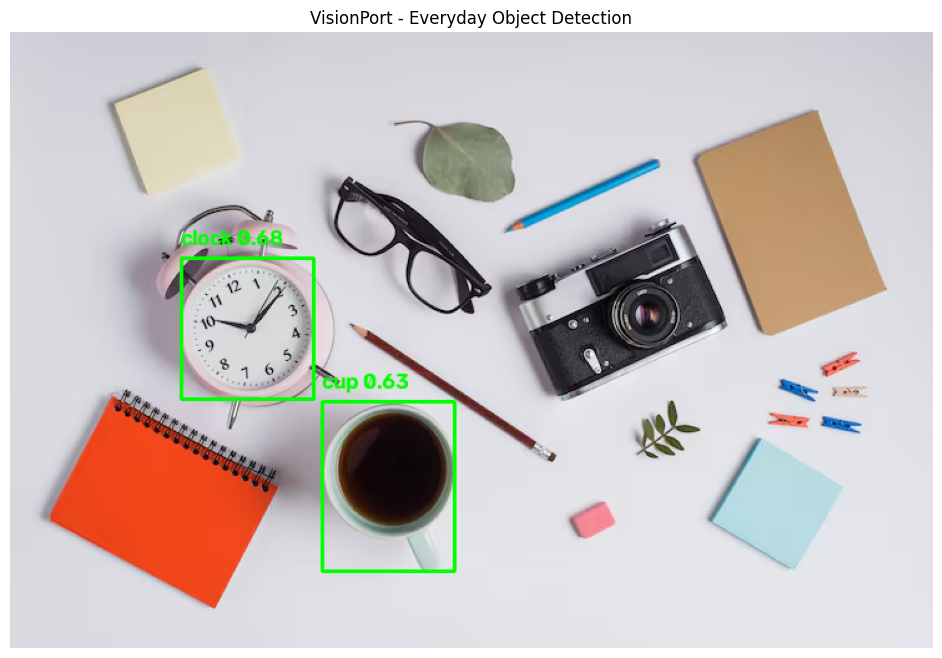

In [43]:
output_image = original_image.copy()

for item in results:

    x1, y1, x2, y2 = map(int, item["box"])

    label = item["object"]
    confidence = item["confidence"]

    cv2.rectangle(
        output_image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output_image,
        f"{label} {confidence:.2f}",
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 8))
plt.imshow(output_image)
plt.axis("off")
plt.title("VisionPort - Everyday Object Detection")
plt.show()

In [44]:
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.testclient import TestClient

print("FastAPI libraries imported successfully!")

FastAPI libraries imported successfully!


In [45]:
app = FastAPI(
    title="VisionPort Object Detection API",
    description="Everyday Object Detection using YOLOv8",
    version="1.0"
)

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    try:

        image_bytes = await file.read()

        response, _, _ = visionport_pipeline(
            file.filename or "",
            file.content_type or "",
            image_bytes
        )

        return json.loads(response)

    except ValueError as error:

        raise HTTPException(
            status_code=400,
            detail=str(error)
        )

    except Exception as error:

        raise HTTPException(
            status_code=500,
            detail=str(error)
        )

print("FastAPI application created successfully!")

FastAPI application created successfully!


In [46]:
client = TestClient(app)

with open(filename, "rb") as image_file:

    api_response = client.post(
        "/predict",
        files={
            "file": (
                filename,
                image_file,
                content_type
            )
        }
    )

print("HTTP Status Code:", api_response.status_code)

print("\nAPI Response:")

print(json.dumps(api_response.json(), indent=4))


========== VISIONPORT PIPELINE ==========

Request validation successful!
Image decoded successfully!
Image shape: (494, 740, 3)
Letterboxing completed!
Resized image shape: (640, 640, 3)
Tensor preparation completed!
Tensor shape: torch.Size([1, 3, 640, 640])
Tensor device: cpu
Model inference completed!
Prediction shape: torch.Size([1, 84, 8400])
Inference time: 270.25 ms
Postprocessing completed!
Objects detected: 2

========== PIPELINE COMPLETED ==========

HTTP Status Code: 200

API Response:
{
    "status": "success",
    "model": "YOLOv8n",
    "inference_time_ms": 270.25,
    "total_objects": 2,
    "detections": [
        {
            "object": "clock",
            "confidence": 0.68,
            "box": [
                137.38,
                181.84,
                243.2,
                294.54
            ]
        },
        {
            "object": "cup",
            "confidence": 0.633,
            "box": [
                250.34,
                296.79,
              

In [47]:
print("""
       USER
         |
         v
      FASTAPI
         |
         v
  Request Validation
         |
         v
    Image Decoding
         |
         v
 Resize / Letterboxing
         |
         v
   Tensor Preparation
         |
         v
   YOLOv8 Model
         |
         v
    GPU / CPU
         |
         v
   Postprocessing
         |
         v
 Response Serialization
         |
         v
     JSON Response
""")


       USER
         |
         v
      FASTAPI
         |
         v
  Request Validation
         |
         v
    Image Decoding
         |
         v
 Resize / Letterboxing
         |
         v
   Tensor Preparation
         |
         v
   YOLOv8 Model
         |
         v
    GPU / CPU
         |
         v
   Postprocessing
         |
         v
 Response Serialization
         |
         v
     JSON Response



In [48]:
stages = [
    ("Image Upload", "JPEG / PNG bytes"),
    ("Image Decoding", "RGB (494, 740, 3)"),
    ("Letterboxing", "RGB (640, 640, 3)"),
    ("Tensor Preparation", "Float32 (1, 3, 640, 640)"),
    ("Model Output", "Float32 (1, 84, 8400)"),
    ("Postprocessing", "N x 6 detections"),
    ("Final Response", "JSON")
]

print("VISIONPORT DATA FLOW\n")

for stage, data_format in stages:
    print(stage, ":", data_format)

VISIONPORT DATA FLOW

Image Upload : JPEG / PNG bytes
Image Decoding : RGB (494, 740, 3)
Letterboxing : RGB (640, 640, 3)
Tensor Preparation : Float32 (1, 3, 640, 640)
Model Output : Float32 (1, 84, 8400)
Postprocessing : N x 6 detections
Final Response : JSON
